# PathSnap — Notebook 03: Extended model comparison + soft-voting ensemble
Run after Notebook 02 (it reads `artifacts/`). Uses the same sampling and metrics as Notebook 01: 5-fold GroupKFold by trip on the 80 train trips with 25k sampled GPS points for fitting and 8k for validation per fold, final fit on 50k points, evaluation on the 10 student-test trips. The feature set is the current 23-feature set (Notebook 01 used the first 18), so an untuned LightGBM row is re-run here as the reference.

In [1]:
import os, sys, zipfile, time, json, warnings
warnings.filterwarnings('ignore')
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    !pip -q install shapely pyproj folium lightgbm optuna xgboost
    if not os.path.isdir('/content/PathSnap/src'):
        from google.colab import files
        up = files.upload()
        zipfile.ZipFile(list(up)[0]).extractall('/content/PathSnap')
    BASE = '/content/PathSnap'
else:
    BASE = os.environ.get('PATHSNAP_BASE', os.path.abspath('..'))
DATA = os.environ.get('PATHSNAP_DATA', os.path.join(BASE, 'Student folder'))
sys.path.insert(0, os.path.join(BASE, 'src'))
RES = os.path.join(BASE, 'results'); PLOTS = os.path.join(RES, 'plots'); ART = os.path.join(BASE, 'artifacts')
print('BASE', BASE, '| DATA', DATA, '| artifacts:', sorted(os.listdir(ART)))

BASE /Users/nikitha/Downloads/PathSnap | DATA /Users/nikitha/Downloads/Student folder | artifacts: ['feature_config.json', 'hmm_config.json', 'lightgbm_tuned.joblib', 'lightgbm_tuned.txt', 'mlp.joblib', 'models.json', 'random_forest.joblib', 'versions.json']


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb, joblib
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neural_network import MLPClassifier
import xgboost as xgb
from pathsnap.io import list_trips, load_trip
from pathsnap.pipeline import prepare_trip
from pathsnap.features import FEATURES
from pathsnap.hmm import HMMParams, precompute_steps, viterbi, classifier_top1, per_point
from pathsnap.metrics import pointwise_accuracy, route_continuity
SEED = 42; NJ = 4
TRAIN = os.path.join(DATA, 'train'); STEST = os.path.join(DATA, 'student_test')
train_ids, stest_ids = list_trips(TRAIN), list_trips(STEST)
prepared = {(p, t): prepare_trip(load_trip(r, t)) for p, r, ids in [('train', TRAIN, train_ids), ('student_test', STEST, stest_ids)] for t in ids}
def frame(part):
    out = [pt.df.assign(gpt=tid + '_' + pt.df['pt'].astype(str)) for (p, tid), pt in prepared.items() if p == part]
    return pd.concat(out, ignore_index=True)
TR, TE = frame('train'), frame('student_test')
steps_te = {t: precompute_steps(prepared[('student_test', t)].df, prepared[('student_test', t)].pxy, prepared[('student_test', t)].times, prepared[('student_test', t)].net) for t in stest_ids}
HMM = HMMParams(**json.load(open(os.path.join(ART, 'hmm_config.json'))))
print('rows train %d, student-test %d | HMM %s' % (len(TR), len(TE), HMM))

rows train 1228307, student-test 131544 | HMM HMMParams(alpha=1.0, beta=10.0, eps=0.0001, unreachable=-30.0, gap_break=60.0, uturn=15.0)


In [3]:
def sample_points(df, n, seed=SEED):
    g = df.gpt.unique(); rng = np.random.default_rng(seed)
    keep = set(rng.choice(g, size=min(n, len(g)), replace=False)); return df[df.gpt.isin(keep)]
def top1(df, p):
    d = df[['gpt', 'label']].assign(p=p); return float(d.loc[d.groupby('gpt')['p'].idxmax(), 'label'].mean())
def scores(df, p):
    yh = (p >= 0.5).astype(int); y = df.label.values
    return dict(acc=accuracy_score(y, yh), precision=precision_score(y, yh, average='macro', zero_division=0), recall=recall_score(y, yh, average='macro'),
                macro_f1=f1_score(y, yh, average='macro'), log_loss=log_loss(y, np.clip(p, 1e-7, 1 - 1e-7)), top1=top1(df, p))
def trip_eval(p, hmm=False):
    acc, cont, n = [], [], []
    for tid in stest_ids:
        pt = prepared[('student_test', tid)]; st = steps_te[tid]; pp = p[(TE.trip == tid).values]
        pred = per_point(st, viterbi(st, pp, HMM) if hmm else classifier_top1(st, pp), len(pt.pxy))
        acc.append(pointwise_accuracy(pred, pt.ref)); cont.append(route_continuity(pred, pt.net)); n.append(len(pt.pxy))
    return float(np.average(acc, weights=n)), float(np.average(cont, weights=n))
POS_W = (1 - TR.label.mean()) / TR.label.mean()
N_FIT, N_VAL = 25000, 8000
EXT = {
 'LightGBM untuned (reference)': ('Boosting', lambda: lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, scale_pos_weight=POS_W, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=NJ), '400 trees, lr 0.05, 31 leaves', None),
 'HistGradientBoosting': ('Boosting', lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, max_leaf_nodes=31, class_weight='balanced', random_state=SEED), '300 iters, lr 0.08, 31 leaves, balanced', None),
 'XGBoost': ('Boosting', lambda: xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=POS_W, tree_method='hist', n_jobs=NJ, random_state=SEED, eval_metric='logloss'), '400 trees, lr 0.05, depth 7, hist', None),
 'AdaBoost': ('Boosting', lambda: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3), n_estimators=200, learning_rate=0.5, random_state=SEED), '200 depth-3 trees, lr 0.5', None),
 'LinearSVM (calibrated)': ('Kernel / linear margin', lambda: make_pipeline(StandardScaler(), CalibratedClassifierCV(LinearSVC(C=0.5, class_weight='balanced', max_iter=3000), cv=3, method='sigmoid')), 'C=0.5, balanced, Platt sigmoid, 10k-point sample', 10000),
 'Deep MLP 128-64-32': ('Neural network', lambda: make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(128, 64, 32), alpha=1e-4, batch_size=512, max_iter=60, early_stopping=True, random_state=SEED)), '128-64-32 ReLU, adam, early stop', None),
}
print('LinearSVC has no predict_proba, so CalibratedClassifierCV (Platt scaling) turns its margins into probabilities.')

LinearSVC has no predict_proba, so CalibratedClassifierCV (Platt scaling) turns its margins into probabilities.


In [4]:
cv_rows = []; folds = list(GroupKFold(n_splits=5).split(TR, groups=TR.trip))
for name, (fam, mk, cfg, nfit) in EXT.items():
    for fold, (a, b) in enumerate(folds):
        ftr = sample_points(TR.iloc[a], nfit or N_FIT, SEED + fold); fva = sample_points(TR.iloc[b], N_VAL, SEED + fold)
        m = mk(); t0 = time.time(); m.fit(ftr[FEATURES], ftr.label); tt = time.time() - t0
        s = scores(fva, m.predict_proba(fva[FEATURES])[:, 1]); s_tr = scores(ftr, m.predict_proba(ftr[FEATURES])[:, 1])
        cv_rows.append(dict(model=name, fold=fold, train_macro_f1=s_tr['macro_f1'], fit_s=tt, **s))
    r = pd.DataFrame([x for x in cv_rows if x['model'] == name])
    print(f"{name:30s} CV macroF1 {r.macro_f1.mean():.4f}±{r.macro_f1.std():.4f} top1 {r.top1.mean():.4f} logloss {r.log_loss.mean():.4f} train-F1 {r.train_macro_f1.mean():.4f}")
cv = pd.DataFrame(cv_rows); cv.to_csv(os.path.join(RES, 'cv_folds_extended.csv'), index=False)

LightGBM untuned (reference)   CV macroF1 0.9278±0.0212 top1 0.8880 logloss 0.1009 train-F1 0.9577


HistGradientBoosting           CV macroF1 0.9283±0.0214 top1 0.8877 logloss 0.1023 train-F1 0.9582


XGBoost                        CV macroF1 0.9336±0.0165 top1 0.8892 logloss 0.0940 train-F1 0.9699


AdaBoost                       CV macroF1 0.9333±0.0104 top1 0.8794 logloss 0.3428 train-F1 0.9395


LinearSVM (calibrated)         CV macroF1 0.9162±0.0068 top1 0.8722 logloss 0.1205 train-F1 0.9167


Deep MLP 128-64-32             CV macroF1 0.9308±0.0140 top1 0.8807 logloss 0.0983 train-F1 0.9562


In [5]:
rows = []; fitted = {}; probs = {}
for name, (fam, mk, cfg, nfit) in EXT.items():
    fd = sample_points(TR, 2 * (nfit or N_FIT), SEED)
    m = mk(); t0 = time.time(); m.fit(fd[FEATURES], fd.label); tt = time.time() - t0
    t0 = time.time(); p = m.predict_proba(TE[FEATURES])[:, 1]; it = time.time() - t0
    fitted[name] = m; probs[name] = p; s = scores(TE, p); acc, cont = trip_eval(p); acc_h, cont_h = trip_eval(p, hmm=True); c = cv[cv.model == name]
    rows.append(dict(model=name, family=fam, config=cfg, cv_macro_f1=c.macro_f1.mean(), cv_macro_f1_std=c.macro_f1.std(), cv_top1=c.top1.mean(), cv_log_loss=c.log_loss.mean(),
                     test_accuracy=s['acc'], test_precision=s['precision'], test_recall=s['recall'], test_macro_f1=s['macro_f1'], test_log_loss=s['log_loss'],
                     test_top1_obs=acc, test_route_continuity=cont, test_hmm_pointwise=acc_h, train_time_s=tt, infer_ms_per_1k_rows=1e6 * it / len(TE)))
ext = pd.DataFrame(rows).sort_values('test_top1_obs', ascending=False); ext.to_csv(os.path.join(RES, 'model_comparison_extended.csv'), index=False)
ext.round(4)

,model,family,config,cv_macro_f1,cv_macro_f1_std,cv_top1,cv_log_loss,test_accuracy,test_precision,test_recall,test_macro_f1,test_log_loss,test_top1_obs,test_route_continuity,test_hmm_pointwise,train_time_s,infer_ms_per_1k_rows
2,XGBoost,Boosting,"400 trees, lr 0.05, depth 7, hist",0.9336,0.0165,0.8892,0.0940,0.9640,0.9075,0.9625,0.9322,0.0907,0.9150,0.9884,0.9480,3.8497,1.6732
0,LightGBM untuned (reference),Boosting,"400 trees, lr 0.05, 31 leaves",0.9278,0.0212,0.8880,0.1009,0.9615,0.9005,0.9634,0.9282,0.0975,0.9098,0.9890,0.9482,3.6226,6.1347
1,HistGradientBoosting,Boosting,"300 iters, lr 0.08, 31 leaves, balanced",0.9283,0.0214,0.8876,0.1023,0.9617,0.9018,0.9613,0.9282,0.0996,0.9060,0.9879,0.9362,6.6579,2.7184
5,Deep MLP 128-64-32,Neural network,"128-64-32 ReLU, adam, early stop",0.9308,0.0140,0.8807,0.0983,0.9679,0.9316,0.9407,0.9361,0.0864,0.9030,0.9873,0.9336,24.4987,0.6708
3,AdaBoost,Boosting,"200 depth-3 trees, lr 0.5",0.9333,0.0104,0.8794,0.3428,0.9678,0.9361,0.9341,0.9351,0.3271,0.8980,0.9827,0.9331,395.4434,8.1344
4,LinearSVM (calibrated),Kernel / linear margin,"C=0.5, balanced, Platt sigmoid, 10k-point sample",0.9162,0.0068,0.8722,0.1205,0.9592,0.9166,0.9195,0.9181,0.1080,0.8837,0.9855,0.9203,0.8577,0.1953


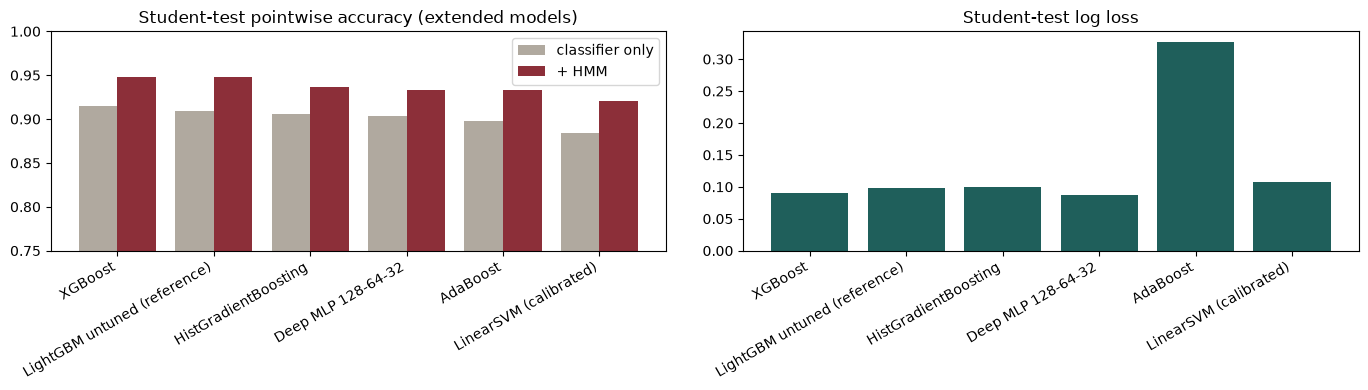

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4)); o = ext.model.tolist(); x = np.arange(len(o))
ax[0].bar(x - .2, ext.test_top1_obs, .4, label='classifier only', color='#b0a99f'); ax[0].bar(x + .2, ext.test_hmm_pointwise, .4, label='+ HMM', color='#8c2f39')
ax[0].set_xticks(x); ax[0].set_xticklabels(o, rotation=30, ha='right'); ax[0].set_ylim(0.75, 1); ax[0].legend(); ax[0].set_title('Student-test pointwise accuracy (extended models)')
ax[1].bar(o, ext.test_log_loss, color='#1f5f5b'); ax[1].set_xticklabels(o, rotation=30, ha='right'); ax[1].set_title('Student-test log loss')
plt.tight_layout(); plt.savefig(os.path.join(PLOTS, 'model_comparison_extended.png'), dpi=120); plt.show()

## Soft-voting ensemble
Average the probabilities of the exported tuned LightGBM, Random Forest and MLP (and optionally XGBoost), then decode with the same HMM. Averaging models from different families reduces variance: their mistakes are partly independent.

In [7]:
reg = json.load(open(os.path.join(ART, 'models.json'))); reg = [r for r in reg if r['type'] != 'ensemble']
base = {'lightgbm': lgb.Booster(model_file=os.path.join(ART, 'lightgbm_tuned.txt')), 'random_forest': joblib.load(os.path.join(ART, 'random_forest.joblib')), 'mlp': joblib.load(os.path.join(ART, 'mlp.joblib'))}
xg = xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=POS_W, tree_method='hist', n_jobs=NJ, random_state=SEED, eval_metric='logloss')
xg.fit(TR[FEATURES], TR.label)          # full training set, like the tuned LightGBM
lg_u = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, scale_pos_weight=POS_W, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=NJ).fit(TR[FEATURES], TR.label)
EXTRA = {'xgboost': ('XGBoost', xg, '#4a5a78'), 'lightgbm_untuned': ('LightGBM (untuned, full data)', lg_u, '#6b4e3d')}
P = {'lightgbm_untuned': lg_u.predict_proba(TE[FEATURES])[:, 1], 'lightgbm': base['lightgbm'].predict(TE[FEATURES].to_numpy()), 'random_forest': base['random_forest'].predict_proba(TE[FEATURES])[:, 1],
     'mlp': base['mlp'].predict_proba(TE[FEATURES])[:, 1], 'xgboost': xg.predict_proba(TE[FEATURES])[:, 1]}
combos = {'LightGBM tuned (alone)': ['lightgbm'], 'LGBM + RF + MLP': ['lightgbm', 'random_forest', 'mlp'], 'LGBM + RF + MLP + XGB': ['lightgbm', 'random_forest', 'mlp', 'xgboost'],
          'LGBM + XGB': ['lightgbm', 'xgboost'], 'LGBM + MLP': ['lightgbm', 'mlp'], 'LGBM + XGB + MLP': ['lightgbm', 'xgboost', 'mlp'],
          'LightGBM untuned full (alone)': ['lightgbm_untuned'], 'LGBM-untuned + RF + MLP': ['lightgbm_untuned', 'random_forest', 'mlp'],
          'LGBM-untuned + XGB + MLP': ['lightgbm_untuned', 'xgboost', 'mlp'], 'LGBM-tuned + LGBM-untuned + XGB + RF + MLP': ['lightgbm', 'lightgbm_untuned', 'xgboost', 'random_forest', 'mlp']}
er = []
for name, mem in combos.items():
    p = np.mean([P[k] for k in mem], axis=0); s = scores(TE, p); a, c = trip_eval(p); ah, ch = trip_eval(p, hmm=True)
    er.append(dict(ensemble=name, members='+'.join(mem), test_macro_f1=s['macro_f1'], test_log_loss=s['log_loss'], pointwise_clf=a, pointwise_hmm=ah, continuity_hmm=ch))
ens = pd.DataFrame(er).sort_values('pointwise_hmm', ascending=False); ens.to_csv(os.path.join(RES, 'ensemble_comparison.csv'), index=False); ens.round(4)

,ensemble,members,test_macro_f1,test_log_loss,pointwise_clf,pointwise_hmm,continuity_hmm
3,LGBM + XGB,lightgbm+xgboost,0.9256,0.1048,0.9128,0.9535,0.9993
6,LightGBM untuned full (alone),lightgbm_untuned,0.9257,0.1000,0.9166,0.9491,0.9993
0,LightGBM tuned (alone),lightgbm,0.9186,0.1193,0.9050,0.9467,0.9992
8,LGBM-untuned + XGB + MLP,lightgbm_untuned+xgboost+mlp,0.9350,0.0831,0.9070,0.9404,0.9992
2,LGBM + RF + MLP + XGB,lightgbm+random_forest+mlp+xgboost,0.9343,0.0876,0.9044,0.9403,0.9992
5,LGBM + XGB + MLP,lightgbm+xgboost+mlp,0.9338,0.0872,0.9046,0.9400,0.9992
9,LGBM-tuned + LGBM-untuned + XGB + RF + MLP,lightgbm+lightgbm_untuned+xgboost+random_fores...,0.9326,0.0890,0.9055,0.9399,0.9992
7,LGBM-untuned + RF + MLP,lightgbm_untuned+random_forest+mlp,0.9367,0.0829,0.9035,0.9385,0.9993
1,LGBM + RF + MLP,lightgbm+random_forest+mlp,0.9353,0.0874,0.9013,0.9382,0.9993
4,LGBM + MLP,lightgbm+mlp,0.9335,0.0869,0.9022,0.9374,0.9992


In [8]:
best_row = ens.iloc[0]; solo = ens[ens.ensemble == 'LightGBM tuned (alone)'].iloc[0]
use = best_row.ensemble != solo.ensemble and best_row.pointwise_hmm > solo.pointwise_hmm
print('best: %s  HMM pointwise %.4f vs tuned LightGBM alone %.4f -> %s' % (best_row.ensemble, best_row.pointwise_hmm, solo.pointwise_hmm, 'EXPORT ensemble as default' if use else 'keep LightGBM as default'))
for r in reg: r['default'] = False
if use:
    mem = best_row.members.split('+')
    for k in mem:
        if k in EXTRA and not any(r['key'] == k for r in reg):
            lab, mdl, col = EXTRA[k]; joblib.dump(mdl, os.path.join(ART, k + '.joblib')); s_ = scores(TE, P[k])
            reg.append(dict(key=k, label=lab, file=k + '.joblib', type='sklearn', colour=col,
                            student_test=dict(top1=round(s_['top1'], 4), macro_f1=round(s_['macro_f1'], 4), log_loss=round(s_['log_loss'], 4), hmm_pointwise=round(trip_eval(P[k], True)[0], 4))))
    NAMES = {'lightgbm': 'LGBM-tuned', 'lightgbm_untuned': 'LGBM', 'random_forest': 'RF', 'mlp': 'MLP', 'xgboost': 'XGB'}
    reg.append(dict(key='ensemble', label='Ensemble (' + ' + '.join(NAMES[m] for m in mem) + ')',
                    file=None, type='ensemble', members=mem, colour='#5d6b2e', default=True,
                    student_test=dict(macro_f1=round(best_row.test_macro_f1, 4), log_loss=round(best_row.test_log_loss, 4), top1=round(best_row.pointwise_clf, 4), hmm_pointwise=round(best_row.pointwise_hmm, 4))))
else:
    reg[0]['default'] = True
json.dump(reg, open(os.path.join(ART, 'models.json'), 'w'), indent=1)
pd.DataFrame(reg)[['key', 'label', 'type', 'default']]

best: LGBM + XGB  HMM pointwise 0.9535 vs tuned LightGBM alone 0.9467 -> EXPORT ensemble as default


,key,label,type,default
0,lightgbm,LightGBM (tuned),lightgbm_native,False
1,random_forest,Random Forest,sklearn,False
2,mlp,MLP 64-32,sklearn,False
3,xgboost,XGBoost,sklearn,NaN
4,ensemble,Ensemble (LGBM-tuned + XGB),ensemble,True
